# Modelo v3: veredito antes de postar

**Projeto Final · Machine Learning Clássico · Prof. Dr. Rodrigo Ramos Silva · 2026**

O v1 (`projeto_final_youtube_shorts.ipynb`) usou metadados de 10.925 Shorts do dataset público e acertou o nível do
canal, mas não a ordem dos vídeos. O v2 (`projeto_final_v2_conteudo.ipynb`) olhou o conteúdo (capa, título, roteiro e
cenas) de 383 Shorts de 54 canais e ficou em AUC ≈ 0,58: pouco dado para muitas features. O v3 muda a escala e a
pergunta: **"este Short vai estourar no meu canal?"**, respondida **antes de postar**, com um veredito que erra pouco
quando diz "VIRAL".

| Item | Escolha |
|---|---|
| Dados | 123.178 Shorts de 523 canais do nicho (explicação animada, "e se", ciência, curiosidade; PT/EN/ES/DE/FR), coletados pela aba Shorts de cada canal + YouTube Data API. Os 54 canais do v2 entraram como sementes |
| Alvo | `viral` = 1 se o Short fez **≥ 5× a régua** do canal (mediana dos 30 Shorts anteriores) **e ≥ 5 mil views**: 9,0% dos Shorts do treino |
| Features | contexto do canal na véspera, título (padrões + vetor multilíngue), capa e 3 quadros do vídeo (vetor CLIP, cor, texto na tela), meta (duração, hora, língua), novidade (parecença com o que o canal já postou) e demanda (temas parecidos em outros canais) |
| Validação | 5 dobras **por canal** (o modelo é sempre testado em canais que nunca viu), limiares escolhidos fora da dobra e teste temporal (treina até mai/2026, testa de jun/2026 em diante) |
| Modelo | par LightGBM (classificador "estoura?" + regressão do múltiplo da régua) combinado pela média dos postos, com calibração isotônica |
| Métricas | ROC AUC, average precision e, principalmente, **precisão do veredito VIRAL** (dos marcados, quantos estouraram) |
| Teste no mundo real | os Shorts do canal *Simulando o Mundo* (auditoria) e ideias de título para os próximos |

**Sobre "clássico".** Os vetores de título (`paraphrase-multilingual-mpnet-base-v2`) e de imagem (CLIP ViT-B/32) são
**extratores de features pré-treinados**, usados congelados, como um "medidor" do texto e da imagem. Quem aprende com
os rótulos é clássico: gradient boosting (LightGBM), regressão ridge (as "cabeças" sobre os vetores) e regressão
isotônica (calibração).

O código está em `src/v3/` (coleta, base, embeddings, quadros, features, treinar, prever). Este notebook **não
retreina** o modelo grande (leva ~15 min): lê os resultados salvos em `reports/v3/` e `data/v3/` e refaz em pequena
escala só a comparação de algoritmos (seção 5).

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ["HF_HUB_OFFLINE"] = "1"                     # usa os modelos de embedding em cache, sem internet
sys.path.insert(0, str(Path.cwd().parent))             # para importar src.v3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore")

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": FUNDO, "axes.facecolor": FUNDO,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": TINTA2,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.titlecolor": TINTA, "axes.titlelocation": "left", "axes.grid": True,
                     "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True})
pd.set_option("display.max_colwidth", 70)

DADOS, RELAT = Path("../data/v3"), Path("../reports/v3")
base = pd.read_parquet(DADOS / "base_v3.parquet")      # uma linha por Short, com rótulo e contexto do canal
val = json.load(open(RELAT / "validacao.json"))        # métricas da validação por canal (src/v3/treinar.py)
oof = pd.read_parquet(DADOS / "oof.parquet")           # notas fora da amostra de cada Short do treino


def br(x, casas=1, pct=False):
    # número no formato brasileiro: 0.386 -> "38,6%" (pct) ou 1234.5 -> "1.234,5"
    v = x * 100 if pct else x
    s = f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return s + ("%" if pct else "")


def top(y, p, frac):
    # dos Shorts com as frac maiores notas, quantos estouraram (precisão no topo)
    k = max(1, int(round(frac * len(y))))
    return float(np.asarray(y)[np.argsort(-np.asarray(p))[:k]].mean())


print(f"base: {len(base):,} Shorts | oof: {len(oof):,} Shorts do treino".replace(",", "."))

base: 123.178 Shorts | oof: 87.338 Shorts do treino


## 1. Os dados

Para cada canal encontrado nas buscas, a coleta lê a **aba Shorts inteira** (yt-dlp, lista plana) e completa com a
YouTube Data API (data de publicação, duração, língua, tags, views). As capas e 3 quadros de cada vídeo (a 25%, 50% e
75% da duração) vêm do CDN de imagens do YouTube. Entram no treino os Shorts de 2022 em diante com pelo menos 14 dias
(views quase finais), régua do canal ≥ 300 views e canal com pelo menos 30 Shorts anteriores e 90 dias (seção 4).

In [2]:
quadros = pd.read_json(DADOS / "quadros_feats.jsonl", lines=True)
quadros = quadros[quadros.get("erro").isna()] if "erro" in quadros else quadros
base = base.merge(quadros[["id", "qd_animado"]].drop_duplicates("id"), on="id", how="left")

treino = base[base["id"].isin(oof["id"])]            # exatamente os Shorts da validação (2022+, régua, cortes da seção 4)
anim_canal = base.groupby("canal_id")["qd_animado"].mean()
print(f"Shorts coletados: {br(len(base), 0)} de {base['canal_id'].nunique()} canais")
print(f"No treino:        {br(len(treino), 0)} de {treino['canal_id'].nunique()} canais")
print(f"Estouraram:       {br(treino['viral'].mean(), 1, pct=True)}")
print(f"Canais animados (quadros parecem animação/3D/desenho para o CLIP, média >= 0,6): "
      f"{(anim_canal >= 0.6).sum()} de {anim_canal.notna().sum()}")
print("\nLínguas no treino:")
print((treino["lingua"].value_counts(normalize=True).head(6) * 100).round(1).astype(str).str.replace(".", ",") + "%")

Shorts coletados: 123.178 de 523 canais
No treino:        87.338 de 367 canais
Estouraram:       9,0%
Canais animados (quadros parecem animação/3D/desenho para o CLIP, média >= 0,6): 229 de 498

Línguas no treino:
lingua
en    49,4%
pt    30,9%
es    12,1%
de     3,7%
fr     3,1%
hi     0,4%
Name: proportion, dtype: str


**Amostra da base** (10 Shorts do treino sorteados). `régua` é a mediana das views dos 30 Shorts anteriores do mesmo
canal; `× régua` é quanto este Short fez em relação a ela; `ctx_p90_rel` mede o quanto o canal costuma ter picos
(seção 3); `tit_hipotese` marca títulos do tipo "e se..."; `qd_animado` é a nota do CLIP para "isto é animação".

In [3]:
amostra = treino.sample(10, random_state=42)
tabela = pd.DataFrame({
    "canal": amostra["canal"].str.slice(0, 22),
    "título": amostra["titulo"].str.slice(0, 60),
    "língua": amostra["lingua"],
    "duração (s)": amostra["duracao_s"].astype(int),
    "views": amostra["views"].astype(int),
    "régua": amostra["regua"].round(0).astype(int),
    "× régua": amostra["outlier"].round(2),
    "viral": amostra["viral"].astype(int),
    "ctx_p90_rel": amostra["ctx_p90_rel"].round(2),
    "tit_hipotese": amostra["tit_hipotese"].astype(int),
    "qd_animado": amostra["qd_animado"].round(2),
}).reset_index(drop=True)
tabela

,canal,título,língua,duração (s),views,régua,× régua,viral,ctx_p90_rel,tit_hipotese,qd_animado
0,Coda,CROAKED ( TADC / The Amazing Digital Circus Ep 8 Animation ),en,13,4619784,2178372,2.12,0,0.88,0,0.78
1,DreamRoot,Did You Notice This About Captain Clark? 🤔 #backrooms #short,en,19,324018,11487,28.21,1,1.34,0,0.48
2,Lucivandi Barbosa Art,#copadomundo #drawing #copa2026,pt,83,1057,1390,0.76,0,0.45,0,0.99
3,Global Education,💪 How Muscles Actually Grow,en,41,508,392,1.30,0,2.90,0,0.27
4,Mundo Gloob,QUANDO TOCA AQUELA MÚSICA ESPECIAL! | Mundo Gloob #Shorts,pt,50,93025,57972,1.60,0,1.20,0,0.68
5,BuzzFeedVideo,"I Tried ""The Morning Shed"" for One Month - Part 2",en,30,20824,17278,1.21,0,0.44,0,0.24
6,SpaceBalls,PROTECTING THE EARTH 🛡️ #planethumans,en,9,1762622,1352386,1.30,0,1.44,0,0.97
7,Homosapiens,Escoge la perla de tu anillo desde la ostra 💍😨 #sabiasque,es,33,507968,45619,11.14,1,5.27,0,0.12
8,Johns Hopkins Medicine,Johns Hopkins ofrece tratamientos innovadores de trasplante,en,61,861,3166,0.27,0,2.23,0,0.11
9,Conhecimento 3.0,Car Street Game Play #usa #china #brasil #automobile,pt,9,96,742,0.13,0,0.63,0,0.94


## 2. O alvo: estourar na régua do próprio canal

No v1, "viral" era estar no top 20% do dataset, e o tamanho do canal decidia quase tudo. Aqui a pergunta é a do
criador: **este Short vai muito além do que o meu canal costuma fazer?**

- `régua` = mediana das views dos 30 Shorts anteriores do canal (só o passado: é o que se sabe na hora de postar);
- `viral` = 1 quando `views ≥ 5 × régua` **e** `views ≥ 5.000`. O piso evita chamar de viral um Short que foi de 120
  para 1.800 views.

No *Simulando o Mundo* (régua ≈ 1.360 views em nov/2026), estourar é passar de ≈ 6.800 views.

In [4]:
print("Distribuição de '× régua' no treino:")
print(treino["outlier"].describe(percentiles=[.5, .8, .9, .95, .99]).round(2).to_string())
print(f"\nTaxa de viral (≥ 5x e ≥ 5 mil): {br(treino['viral'].mean(), 1, pct=True)}")
print(f"Só ≥ 5x, sem o piso de 5 mil:   {br((treino['outlier'] >= 5).mean(), 1, pct=True)}")

Distribuição de '× régua' no treino:
count    87338.00
mean         6.33
std        118.19
min          0.00
50%          0.99
80%          2.27
90%          4.65
95%         10.20
99%         60.88
max      14655.12

Taxa de viral (≥ 5x e ≥ 5 mil): 9,0%
Só ≥ 5x, sem o piso de 5 mil:   9,4%


## 3. O canal na véspera: quem tem picos tem mais picos

A feature mais forte do modelo é `ctx_p90_rel`: o quanto o percentil 90 das views dos últimos 30 Shorts se afasta da
mediana (em log). Canal regular (tudo dá mais ou menos o mesmo número) quase nunca dá um salto de 5×.

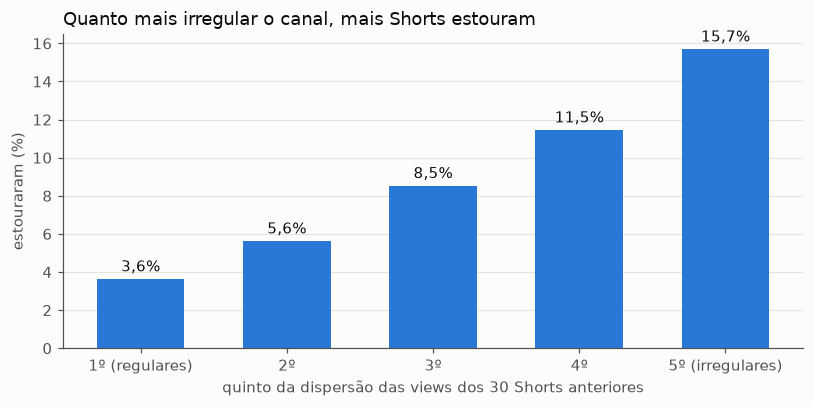

,p90_rel_de,p90_rel_ate,taxa_viral,shorts
quinto,,,,
1º (regulares),0.082,0.724,"3,6%",17406
2º,0.724,1.075,"5,6%",17404
3º,1.075,1.465,"8,5%",17433
4º,1.465,2.014,"11,5%",17374
5º (irregulares),2.014,7.971,"15,7%",17404


In [5]:
d = treino.dropna(subset=["ctx_p90_rel"]).copy()
d["quinto"] = pd.qcut(d["ctx_p90_rel"], 5, labels=["1º (regulares)", "2º", "3º", "4º", "5º (irregulares)"])
disp = d.groupby("quinto", observed=True).agg(p90_rel_de=("ctx_p90_rel", "min"), p90_rel_ate=("ctx_p90_rel", "max"),
                                              taxa_viral=("viral", "mean"), shorts=("viral", "size"))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(range(5), disp["taxa_viral"] * 100, width=0.6, color=AZUL)
for i, v in enumerate(disp["taxa_viral"]):
    ax.text(i, v * 100 + 0.4, br(v, 1, pct=True), ha="center", color=TINTA, fontsize=10)
ax.set_xticks(range(5), disp.index)
ax.grid(axis="x", visible=False)
ax.set(title="Quanto mais irregular o canal, mais Shorts estouram", ylabel="estouraram (%)",
       xlabel="quinto da dispersão das views dos 30 Shorts anteriores")
plt.tight_layout(); plt.show()
disp.assign(taxa_viral=disp["taxa_viral"].map(lambda x: br(x, 1, pct=True))).round(3)

O Simulando tem dispersão 0,63: está no 1º quinto, onde só 3,6% dos Shorts estouram. É por isso que as chances do
canal ficam perto da média, mesmo com conteúdo bom.

## 4. Cuidados contra vazamento (números bonitos e falsos)

Três armadilhas apareceram no caminho. Em todas, a correção **baixou** a métrica e foi mantida, porque o número de antes
não se repetiria na vida real.

**(a) O futuro dos vizinhos.** As features do canal usavam Shorts com 2 dias, mas com as views *finais* (as da coleta).
Na véspera, um Short de 2 dias ainda não mostrou o que vai fazer: o modelo aprendia "o canal está numa onda" com
informação que ninguém tinha. Agora só entram Shorts com ≥ 7 dias (views quase finais).

In [6]:
exp = Path("../data/v3/exp")
v2d = json.load(open(exp / "validacao_rapido_todos.json"))["tudo"]
v7d = json.load(open(exp / "validacao_final_maturo7.json"))["tudo"]
pd.DataFrame({"Shorts do canal com ≥ 2 dias (vazava)": v2d, "com ≥ 7 dias (honesto)": v7d}).loc[
    ["auc", "ap", "auc_dentro_canal", "prec_top1%", "prec_top5%"]].astype(float).round(3)

,Shorts do canal com ≥ 2 dias (vazava),com ≥ 7 dias (honesto)
auc,0.737,0.710
ap,0.229,0.197
auc_dentro_canal,0.651,0.619
prec_top1%,0.422,0.335
prec_top5%,0.311,0.273


**(b) Viés de sobrevivência.** A coleta encontra canais que **deram certo** (é o que a busca do YouTube mostra). Então
o começo deles parece promissor demais: os primeiros Shorts estouram mais do que os de canais maduros. A tabela usa
todos os Shorts com régua (sem o corte do treino) para mostrar o efeito. No primeiro modelo, os 5 Shorts recentes do
Simulando saíram todos PROMISSOR (22% a 31%) e nenhum estourou. Correção: Shorts com menos de 30 anteriores ou de canal
com menos de 90 dias saíram do treino, e a idade do canal e o nº de Shorts anteriores saíram das features (num canal
novo, como o Simulando, com 9 dias, elas só extrapolariam).

In [7]:
todos = base[base["outlier"].notna() & (base["regua"] >= 300) & (base["idade_dias"] >= 14)
             & (base["publicado"] >= pd.Timestamp("2022-01-01", tz="UTC"))]
por_idade = todos.groupby(pd.cut(todos["ctx_idade_canal_dias"], [-1, 30, 90, 180, 365, 730, 1e6],
                                 labels=["≤ 30 d", "31–90 d", "91–180 d", "181–365 d", "1–2 anos", "> 2 anos"]),
                          observed=True)["viral"].agg(taxa_viral="mean", shorts="size")
por_n = todos.groupby(pd.cut(todos["ctx_n_anteriores"], [9, 15, 20, 30, 50, 100, 200, 1e6],
                             labels=["10–15", "16–20", "21–30", "31–50", "51–100", "101–200", "> 200"]),
                      observed=True)["viral"].agg(taxa_viral="mean", shorts="size")
fmt = lambda t: t.assign(taxa_viral=t["taxa_viral"].map(lambda x: br(x, 1, pct=True)))
display(fmt(por_idade).rename_axis("idade do canal na postagem"))
fmt(por_n).rename_axis("nº de Shorts anteriores")

,taxa_viral,shorts
idade do canal na postagem,,
≤ 30 d,"13,5%",1142
31–90 d,"11,2%",1558
91–180 d,"9,1%",1858
181–365 d,"9,0%",3149
1–2 anos,"9,4%",4231
> 2 anos,"9,1%",84538


,taxa_viral,shorts
nº de Shorts anteriores,,
10–15,"11,4%",2378
16–20,"12,1%",1870
21–30,"11,2%",3469
31–50,"10,7%",6255
51–100,"10,5%",13452
101–200,"9,4%",21071
> 200,"8,2%",47981


**(c) Só canais animados ou a base inteira?** Treinar só com os canais animados (o nicho do Simulando) foi pior do que
treinar com tudo, **mesmo medindo só nos animados**: mais dados venceram a especialização (experimento com a versão
anterior das features; os dois modelos avaliados nos mesmos Shorts).

In [8]:
o_todos = pd.read_parquet(exp / "oof_rapido_todos.parquet")[["id", "viral", "p_tudo"]]
o_anim = pd.read_parquet(exp / "oof_rapido_animados.parquet")[["id", "p_tudo"]]
m = o_todos.merge(o_anim, on="id", suffixes=("_base_inteira", "_so_animados"))
pd.DataFrame([{"treinado com": nome, "Shorts avaliados (animados)": len(m),
               "AUC": roc_auc_score(m["viral"], m[c]), "AP": average_precision_score(m["viral"], m[c]),
               "precisão top 1%": top(m["viral"], m[c], 0.01)}
              for nome, c in (("base inteira (461 canais)", "p_tudo_base_inteira"),
                              ("só canais animados (209)", "p_tudo_so_animados"))]).set_index("treinado com").round(3)

,Shorts avaliados (animados),AUC,AP,precisão top 1%
treinado com,,,,
base inteira (461 canais),34344,0.737,0.228,0.408
só canais animados (209),34344,0.720,0.214,0.385


## 5. Comparação de algoritmos

Como no v1 e no v2, os algoritmos da disciplina lado a lado, com a mesma validação por canal. Para caber no notebook,
usa uma amostra de 150 canais do treino e as features que não dependem de rótulo (sem a demanda e sem as "cabeças"
ridge, que no modelo final são refeitas dentro de cada dobra). O LightGBM é o mesmo algoritmo do modelo final, só que
sozinho e com menos árvores.

In [9]:
import time
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from src.v3 import treinar as T
from src.v3.features import GRUPOS

t0 = time.time()
df_, X_, Et_, vet_, msk_, proj_, treino_ = T.preparar()     # mesma matriz de features do treino (sem rótulo)
cols = [c for c in T.colunas([g for g in GRUPOS if g != "demanda"]) if c in X_.columns]
canais_tr = df_.loc[treino_, "canal_id"].unique()
escolhidos = set(np.random.default_rng(42).choice(canais_tr, 150, replace=False))
linha = treino_ & df_["canal_id"].isin(escolhidos).to_numpy()
Xa, ya, ga = X_.loc[linha, cols].to_numpy(np.float32), df_.loc[linha, "viral"].to_numpy(int), df_.loc[linha, "canal_id"].to_numpy()
print(f"amostra: {br(len(ya), 0)} Shorts de {len(escolhidos)} canais, {len(cols)} features, "
      f"viral {br(ya.mean(), 1, pct=True)}  [{time.time() - t0:.0f} s]")

modelos = {
    "Regressão Logística": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                                 LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")),
    "Árvore de Decisão": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                               DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=42)),
    "Random Forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt",
                                                                  n_jobs=-1, random_state=42)),
    "LightGBM": lambda: lgb.LGBMClassifier(n_estimators=300, **T.PARAMS),
}
oof_alg = {n: np.zeros(len(ya)) for n in modelos}
for tr, te in GroupKFold(5).split(Xa, ya, ga):           # nenhum canal no treino e no teste ao mesmo tempo
    for nome, criar in modelos.items():
        oof_alg[nome][te] = criar().fit(Xa[tr], ya[tr]).predict_proba(Xa[te])[:, 1]
comp = pd.DataFrame([{"modelo": n, "AUC": roc_auc_score(ya, p), "AP": average_precision_score(ya, p),
                      "precisão top 1%": top(ya, p, 0.01), "precisão top 5%": top(ya, p, 0.05)}
                     for n, p in oof_alg.items()]).set_index("modelo").round(3)
print(f"tempo: {(time.time() - t0) / 60:.1f} min")
comp

amostra: 36.572 Shorts de 150 canais, 125 features, viral 8,8%  [66 s]


tempo: 1.7 min


,AUC,AP,precisão top 1%,precisão top 5%
modelo,,,,
Regressão Logística,0.670,0.172,0.301,0.245
Árvore de Decisão,0.636,0.143,0.216,0.210
Random Forest,0.687,0.182,0.331,0.275
LightGBM,0.685,0.176,0.306,0.256


**Leitura.** Os dois ensembles de árvores (Random Forest e LightGBM) empatam em AUC (≈ 0,69) e ficam à frente da
Regressão Logística (0,67) e bem à frente da árvore única (0,64). Nesta amostra a Random Forest foi um pouco melhor
no top 1%, diferença do tamanho do ruído de 150 canais. O LightGBM ficou no modelo final porque treina rápido o
bastante para as dezenas de ajustes da validação aninhada, da ablação e do teste temporal, lida sozinho com valores
ausentes (capas e quadros que faltam) e permite a regressão robusta (huber) do múltiplo da régua, que forma o par com
o classificador. Com o par, as features de demanda e as cabeças, a base inteira chega a AUC 0,698 (seção 6).

## 6. Ablação: o que cada grupo de features acrescenta

Modelo final (par classificador + regressão), 87.338 Shorts de 367 canais, 5 dobras por canal. Cada linha acrescenta
um grupo à anterior.

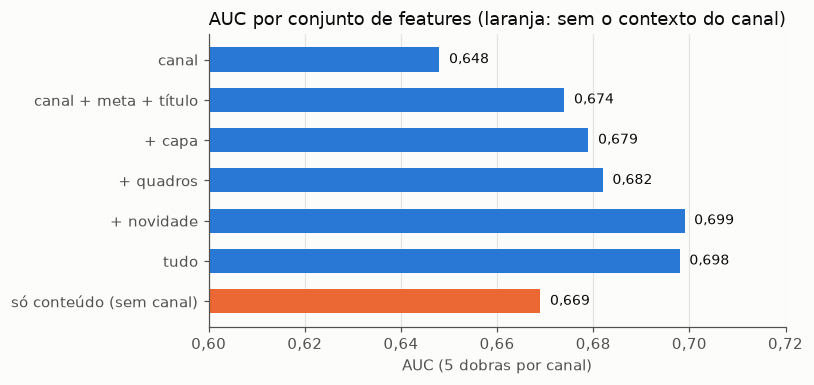

,AUC,AP,AUC dentro do canal,precisão top 1%,precisão top 5%
conjunto,,,,,
canal,0.648,0.150,0.583,0.265,0.200
canal + meta + título,0.674,0.172,0.612,0.322,0.244
+ capa,0.679,0.175,0.619,0.323,0.244
+ quadros,0.682,0.177,0.625,0.328,0.251
+ novidade,0.699,0.195,0.642,0.392,0.277
tudo,0.698,0.195,0.643,0.379,0.275
só conteúdo (sem canal),0.669,0.175,0.621,0.320,0.254


In [10]:
ordem = ["canal", "canal + meta + título", "+ capa", "+ quadros", "+ novidade", "tudo", "só conteúdo (sem canal)"]
abl = pd.DataFrame([{"conjunto": k, "AUC": val[k]["auc"], "AP": val[k]["ap"], "AUC dentro do canal": val[k]["auc_dentro_canal"],
                     "precisão top 1%": val[k]["prec_top1%"], "precisão top 5%": val[k]["prec_top5%"]} for k in ordem]
                   ).set_index("conjunto").round(3)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(abl.index[::-1], abl["AUC"][::-1], color=[LARANJA if k == "só conteúdo (sem canal)" else AZUL for k in abl.index[::-1]],
        height=0.6)
for i, v in enumerate(abl["AUC"][::-1]):
    ax.text(v + 0.002, i, br(v, 3), va="center", color=TINTA, fontsize=9)
ax.set_xlim(0.6, 0.72)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v, 2)))
ax.grid(axis="y", visible=False)
ax.set(title="AUC por conjunto de features (laranja: sem o contexto do canal)", xlabel="AUC (5 dobras por canal)")
plt.tight_layout(); plt.show()
abl

O contexto do canal sozinho dá AUC 0,648. O conteúdo soma +0,05 e é o que separa um Short do outro **no mesmo canal**
(AUC dentro do canal de 0,583 para 0,643). Sozinho, sem saber nada do canal, o conteúdo já chega a 0,669. O grupo que
mais acrescenta é a **novidade**: o quanto o título e a capa se parecem com os Shorts anteriores do canal e como esses
parecidos foram. A **demanda** (temas parecidos em outros canais) não acrescenta nada além do resto. Fica no modelo
porque é útil na saída do `prever`.

## 7. A decisão VIRAL com poucos falsos positivos

O limiar de cada veredito é escolhido em 4 dobras e aplicado na 5ª (*cross-fitting*): a precisão abaixo **não** foi
ajustada nos mesmos vídeos em que foi medida.

In [11]:
dec = pd.DataFrame(val["tudo"]["decisao_viral"])
tab = pd.DataFrame({
    "precisão buscada": dec["alvo"].map(lambda x: br(x, 0, pct=True)),
    "marcados como VIRAL": dec["previstos_virais"],
    "% dos Shorts": dec["cobertura"].map(lambda x: br(x, 2, pct=True)),
    "acertos": dec["acertos"],
    "falsos positivos": dec["falsos_positivos"],
    "precisão real": dec["precisao"].map(lambda x: br(x, 1, pct=True)),
    "recall": dec["recall"].map(lambda x: br(x, 1, pct=True)),
})
nv = val["tudo"]["decisao_nao_viral"]
print(f"Veredito VIRAL do prever = alvo {val['alvo_viral']}; PROMISSOR = alvo 0.2")
print(f"NÃO VIRAL: {br(nv['cobertura'], 1, pct=True)} dos Shorts; {br(nv['taxa_viral_entre_eles'], 1, pct=True)} deles "
      f"estouram; deixa passar {br(nv['virais_perdidos_frac'], 1, pct=True)} dos que estouram")
tab

Veredito VIRAL do prever = alvo 0.4; PROMISSOR = alvo 0.2
NÃO VIRAL: 36,4% dos Shorts; 3,6% deles estouram; deixa passar 14,5% dos que estouram


,precisão buscada,marcados como VIRAL,% dos Shorts,acertos,falsos positivos,precisão real,recall
0,20%,14809,"16,96%",2961,11848,"20,0%","37,6%"
1,25%,6477,"7,42%",1615,4862,"24,9%","20,5%"
2,30%,2913,"3,34%",869,2044,"29,8%","11,0%"
3,35%,1355,"1,55%",465,890,"34,3%","5,9%"
4,40%,731,"0,84%",282,449,"38,6%","3,6%"
5,50%,70,"0,08%",28,42,"40,0%","0,4%"


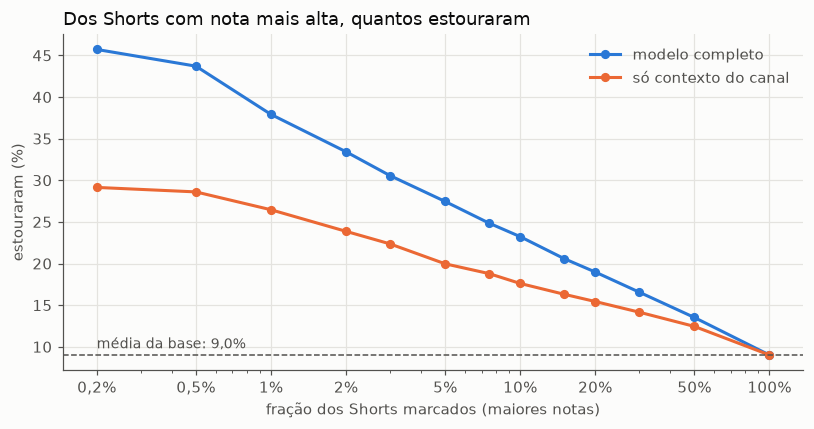

In [12]:
y = oof["viral"].to_numpy()
fr = np.array([0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0])
fig, ax = plt.subplots(figsize=(7.5, 4))
for col, nome, cor in (("p_tudo", "modelo completo", AZUL), ("p_canal", "só contexto do canal", LARANJA)):
    ax.plot(fr * 100, [top(y, oof[col], f) * 100 for f in fr], color=cor, lw=2, marker="o", ms=5, label=nome)
ax.axhline(y.mean() * 100, color=TINTA2, lw=1, ls="--")
ax.text(0.2, y.mean() * 100 + 0.8, f"média da base: {br(y.mean(), 1, pct=True)}", color=TINTA2, fontsize=9)
ax.set_xscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100], ["0,2%", "0,5%", "1%", "2%", "5%", "10%", "20%", "50%", "100%"])
ax.set(title="Dos Shorts com nota mais alta, quantos estouraram", xlabel="fração dos Shorts marcados (maiores notas)",
       ylabel="estouraram (%)")
ax.legend(frameon=False, labelcolor=TINTA2)
plt.tight_layout(); plt.show()

Quando o modelo diz **VIRAL**, 38,6% estouram: 4,3 vezes a média (9,0%). Acima disso a precisão não sobe: a cada 5
marcados, 3 não estouram. Esse é o teto honesto de um preditor pré-publicação, porque boa parte do resultado de um Short
é decidida pela reação das primeiras pessoas a quem o YouTube o mostra, e isso não está no vídeo. O custo da precisão é
o recall: só 3,6% dos que estouram recebem VIRAL antes. O veredito mais útil no dia a dia é o **NÃO VIRAL**, que tira
36% das ideias com só 3,6% de estouro entre elas.

**Por fatia** (mesmo modelo, Shorts de cada grupo):

In [13]:
fatias = {"todos": val["tudo"], "canais animados": val["tudo"]["canais_animados"], "em português": val["tudo"]["portugues"],
          "canais pequenos (régua < 5 mil)": val["tudo"]["canal_pequeno_regua_lt_5k"],
          "animados e pequenos (o caso do Simulando)": val["tudo"]["animado_pequeno"]}
pd.DataFrame([{"fatia": k, "Shorts": r["n"], "taxa base": br(r["taxa_viral"], 1, pct=True), "AUC": round(r["auc"], 3),
               "AUC dentro do canal": round(r["auc_dentro_canal"], 3), "precisão top 1%": br(r["prec_top1%"], 1, pct=True)}
              for k, r in fatias.items()]).set_index("fatia")

,Shorts,taxa base,AUC,AUC dentro do canal,precisão top 1%
fatia,,,,,
todos,87338,"9,0%",0.698,0.643,"37,9%"
canais animados,30357,"8,4%",0.697,0.644,"35,2%"
em português,26996,"9,2%",0.703,0.653,"33,0%"
canais pequenos (régua < 5 mil),30985,"6,9%",0.719,0.643,"36,8%"
animados e pequenos (o caso do Simulando),7477,"5,3%",0.698,0.624,"22,7%"


## 8. Calibração e teste temporal

**Calibração:** a chance que o `prever` mostra vem de uma regressão isotônica sobre a nota. Para medir sem otimismo, a
isotônica de cada dobra é ajustada nas outras 4 e aplicada nela.

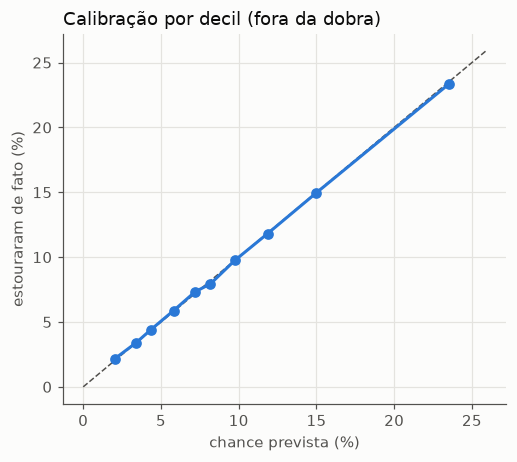

,prevista,real,shorts
q,,,
0,"2,0%","2,2%",9183
1,"3,4%","3,4%",8843
2,"4,3%","4,4%",8742
3,"5,8%","5,9%",8496
4,"7,2%","7,3%",8568
5,"8,2%","7,9%",8606
6,"9,7%","9,7%",9092
7,"11,9%","11,8%",9209
8,"15,0%","14,9%",7981


In [14]:
s, dobra = oof["p_tudo"].to_numpy(), oof["dobra"].to_numpy()
p_cal = np.zeros(len(y))
for k in np.unique(dobra):
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s[dobra != k], y[dobra != k])
    p_cal[dobra == k] = iso.predict(s[dobra == k])
dec_cal = pd.DataFrame({"q": pd.qcut(p_cal, 10, labels=False, duplicates="drop"), "p": p_cal, "y": y}).groupby("q").agg(
    prevista=("p", "mean"), real=("y", "mean"), shorts=("y", "size"))
fig, ax = plt.subplots(figsize=(4.8, 4.3))
lim = dec_cal[["prevista", "real"]].max().max() * 110
ax.plot([0, lim], [0, lim], color=TINTA2, lw=1, ls="--")
ax.plot(dec_cal["prevista"] * 100, dec_cal["real"] * 100, color=AZUL, lw=2, marker="o", ms=6)
ax.set(title="Calibração por decil (fora da dobra)", xlabel="chance prevista (%)", ylabel="estouraram de fato (%)")
plt.tight_layout(); plt.show()
dec_cal.assign(prevista=dec_cal["prevista"].map(lambda x: br(x, 1, pct=True)),
               real=dec_cal["real"].map(lambda x: br(x, 1, pct=True)))

**Teste temporal:** treina com os Shorts publicados até maio/2026 (em 70% dos canais) e testa nos publicados de junho em
diante, nos outros 30% dos canais. Se o modelo estivesse decorando uma época, cairia aqui.

In [15]:
tt, cv = val["teste_temporal"], val["tudo"]
pd.DataFrame({"validação por canal": cv, "teste temporal (jun/2026+)": tt}).loc[
    ["n", "taxa_viral", "auc", "ap", "auc_dentro_canal", "prec_top1%", "prec_top5%"]].astype(float).round(3)

,validação por canal,teste temporal (jun/2026+)
n,87338.000,6510.000
taxa_viral,0.090,0.098
auc,0.698,0.696
ap,0.195,0.193
auc_dentro_canal,0.643,0.616
prec_top1%,0.379,0.354
prec_top5%,0.275,0.276


## 9. O que pesa na nota

Importância por ganho do classificador final (fração do ganho total). As features `ctx_*` são do contexto do canal,
`nov_*` da novidade, `head_*` as cabeças ridge sobre os vetores de título, capa e quadros.

Por grupo: canal 41,5%, novidade 16,5%, título 15,8%, quadros 13,4%, capa 6,0%, meta 3,5%, demanda 3,3%


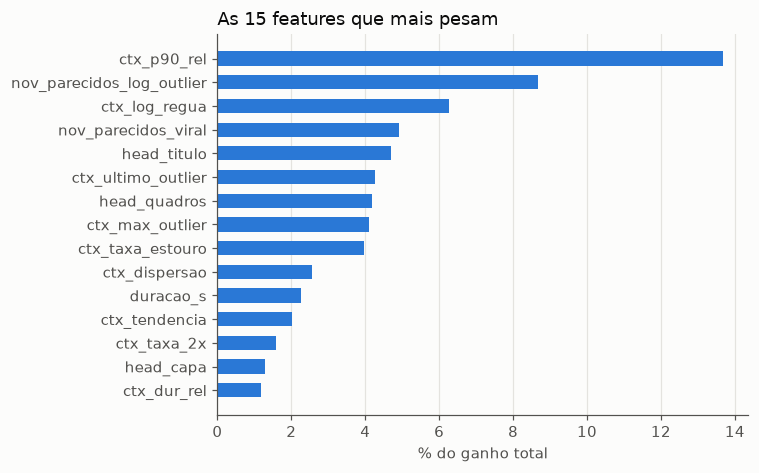

In [16]:
imp = pd.read_csv(RELAT / "importancia_ganho.csv", index_col=0).iloc[:, 0]
imp = (imp / imp.sum()).sort_values(ascending=False)
grupo = pd.Series(val["importancia_grupo"]).sort_values(ascending=False)
print("Por grupo:", ", ".join(f"{k} {br(v, 1, pct=True)}" for k, v in grupo.items()))
fig, ax = plt.subplots(figsize=(7, 4.4))
t15 = imp.head(15)[::-1]
ax.barh(t15.index, t15.values * 100, color=AZUL, height=0.6)
ax.grid(axis="y", visible=False)
ax.set(title="As 15 features que mais pesam", xlabel="% do ganho total")
plt.tight_layout(); plt.show()

## 10. Teste no canal *Simulando o Mundo*

O canal foi criado em 05/11/2026 e tinha 15 Shorts públicos (820 a ~2.950 views, régua ≈ 1.360). **Auditoria**: para
cada Short, o modelo vê só o que existia antes dele (os Shorts anteriores e as views que tinham, o título, a capa e os
quadros publicados). Precisam de 10 anteriores, então só os 5 últimos entram.

In [17]:
aud = pd.DataFrame(json.load(open(DADOS / "auditoria_simulando.json"))["linhas"])
aud.assign(prob=aud["prob"].map(lambda x: br(x, 1, pct=True))).drop(columns="nota_bruta").rename(
    columns={"x_regua": "× régua", "prob": "chance prevista"})

,publicado,titulo,views,× régua,chance prevista,veredito
0,2026-11-10 00:00,E se um terremoto subisse um ponto a cada 5 segundos?,820,0.52,"14,2%",NEUTRO
1,2026-11-10 15:00,E se o meteoro da Rússia explodisse sobre São Paulo?,1205,0.88,"14,2%",NEUTRO
2,2026-11-10 21:00,E se uma barra de tungstênio caísse do espaço?,1246,0.91,"12,5%",NEUTRO
3,2026-11-11 00:00,E se a Terra parasse de girar agora?,1348,0.99,"12,1%",NEUTRO
4,2026-11-11 15:00,E se o Sol sumisse agora?,2956,2.18,"6,5%",NEUTRO


Nenhum falso positivo: nada foi marcado VIRAL ou PROMISSOR, e nada estourou. O modelo antes da correção do viés de
sobrevivência teria marcado os 5 como PROMISSOR. A ordem entre eles **não bateu**: o de maior resultado ("Sol", 2,18×)
levou a menor nota. Com 5 vídeos isso diz pouco (na base, entre um Short que estourou e um que não estourou do mesmo
canal, o que estourou leva a nota maior 64% das vezes), mas é o ponto mais fraco num canal novo.

**Ideias de título para os próximos** (sem vídeo nem capa: o `prever` supõe o visual médio dos últimos Shorts do canal;
postagem em 14/11 às 18h):

In [18]:
ideias = pd.DataFrame(json.load(open(DADOS / "ideias_simulando.json"))).sort_values("prob_estourar", ascending=False)
pd.DataFrame({"ideia": ideias["titulo"], "chance de estourar": ideias["prob_estourar"].map(lambda x: br(x, 1, pct=True)),
              "views esperadas": (ideias["multiplo_previsto"] * ideias["regua_canal"]).round(-1).astype(int),
              "veredito": ideias["veredito"]}).reset_index(drop=True)

,ideia,chance de estourar,views esperadas,veredito
0,E se você caísse num buraco negro?,"11,6%",1690,NEUTRO
1,E se um asteroide caísse no meio do Atlântico?,"11,6%",1690,NEUTRO
2,E se todo o gelo da Antártida derretesse hoje?,"9,2%",1570,NEUTRO
3,E se os humanos sumissem da Terra?,"8,1%",1540,NEUTRO
4,E se você ficasse 1 ano sem dormir?,"6,5%",1320,NEUTRO
5,E se a internet acabasse para sempre?,"5,4%",1300,NÃO VIRAL


## 11. Conclusões do v3

1. **Dá para dizer algo útil antes de postar, mas não com certeza.** Quando o modelo diz VIRAL, 38,6% estouram (4,3× a
   média de 9,0%), medido fora da amostra em canais nunca vistos. Acima de ~40% a precisão não sobe: é o teto de um
   preditor pré-publicação.
2. **O veredito mais útil é o NÃO VIRAL**: 36% das ideias, com 3,6% de estouro entre elas. Serve para cortar ideias
   fracas antes de produzir.
3. **A chance é confiável** (calibração: 23,5% previsto, 23,4% real no decil de cima) e **estável no tempo** (teste
   temporal com AUC 0,696 contra 0,698).
4. **O canal pesa mais que o vídeo.** Canais regulares estouram 3,6% das vezes; irregulares, 15,7%. O conteúdo soma
   +0,05 de AUC e é o que diferencia os Shorts de um mesmo canal (AUC dentro do canal 0,643).
5. **Escala venceu nicho.** De 383 Shorts (v2, AUC 0,58) para 87 mil; treinar só com canais animados foi pior que com
   a base inteira.
6. **Os números honestos são menores que os primeiros.** Corte de 7 dias, viés de sobrevivência e calibração fora da
   dobra baixaram as métricas, e é com eles que o `prever` funciona.

**Limitações:** o conteúdo do vídeo entra por 3 quadros, sem áudio, narração, ritmo de cortes nem retenção (baixar os
vídeos em massa esbarra no bloqueio de robô do YouTube, que não foi contornado); a base tem viés para canais que deram
certo, mesmo com os cortes; o Simulando tem 9 dias e 15 Shorts, então o contexto do canal dele ainda é curto. Vale
retreinar e auditar de novo quando ele tiver uns 30 Shorts com mais de 7 dias. Depois de postar, o preditor de momento
(views das primeiras horas, repositório `videos/`) confirma o veredito: acerta 81% com 3 h e 91% com 12 h.